# Hate Speech Detection using Support Vector Machine (SVM)

**Objective:** Build a machine learning model to classify text into three categories:
- **0 -> Hate Speech**
- **1 -> Offensive Language**
- **2 -> Neither**

**Algorithm:** Support Vector Machine (LinearSVC)  
**Feature Extraction:** TF-IDF Vectorization  
**Dataset:** `labeled_data.csv`

---
## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import re
import string
import pickle
import os

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


---
## 2. Load Dataset

The dataset `labeled_data.csv` is located in the `data/` folder.  
We load it using pandas and inspect the first and last few rows.

In [2]:
# Build a robust path that works from the notebooks directory
NOTEBOOK_DIR = os.path.dirname(os.path.abspath("__file__"))
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, ".."))
DATA_PATH    = os.path.join(PROJECT_ROOT, "data", "labeled_data_actual.csv")

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")
print(f"Path used: {DATA_PATH}")

Dataset loaded successfully.
Path used: C:\Users\snsadmin\Desktop\Hate_Speech_Detection\data\labeled_data_actual.csv


In [3]:
df.head()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [4]:
df.tail()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
24778,25291,3,0,2,1,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...
24779,25292,3,0,1,2,2,"you've gone and broke the wrong heart baby, an..."
24780,25294,3,0,3,0,1,young buck wanna eat!!.. dat nigguh like I ain...
24781,25295,6,0,6,0,1,youu got wild bitches tellin you lies
24782,25296,3,0,0,3,2,~~Ruffled | Ntac Eileen Dahlia - Beautiful col...


---
## 3. Understand Dataset

### 3.1 Dataset Shape

In [5]:
print("Dataset Shape:", df.shape)
print(f"  Number of rows    : {df.shape[0]}")
print(f"  Number of columns : {df.shape[1]}")

Dataset Shape: (24783, 7)
  Number of rows    : 24783
  Number of columns : 7


### 3.2 Dataset Information

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Unnamed: 0          24783 non-null  int64
 1   count               24783 non-null  int64
 2   hate_speech         24783 non-null  int64
 3   offensive_language  24783 non-null  int64
 4   neither             24783 non-null  int64
 5   class               24783 non-null  int64
 6   tweet               24783 non-null  str  
dtypes: int64(6), str(1)
memory usage: 1.3 MB


### 3.3 Column Names

In [7]:
print("Columns:", df.columns.tolist())

Columns: ['Unnamed: 0', 'count', 'hate_speech', 'offensive_language', 'neither', 'class', 'tweet']


### 3.4 First Few Records

In [8]:
df.head()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


### 3.5 Statistical Summary

In [9]:
df.describe(include="all")

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
count,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000,24783
unique,NaN,NaN,NaN,NaN,NaN,NaN,24783
top,NaN,NaN,NaN,NaN,NaN,NaN,!!! RT @mayasolovely: As a woman you shouldn't...
freq,NaN,NaN,NaN,NaN,NaN,NaN,1
mean,12681.192027,3.243473,0.280515,2.413711,0.549247,1.110277,NaN
std,7299.553863,0.883060,0.631851,1.399459,1.113299,0.462089,NaN
min,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,6372.500000,3.000000,0.000000,2.000000,0.000000,1.000000,NaN
50%,12703.000000,3.000000,0.000000,3.000000,0.000000,1.000000,NaN
75%,18995.500000,3.000000,0.000000,3.000000,0.000000,1.000000,NaN


---
## 4. Data Quality Check

Before training, we verify that the dataset does not contain missing values or duplicate records.

### 4.1 Missing Values

In [10]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Unnamed: 0            0
count                 0
hate_speech           0
offensive_language    0
neither               0
class                 0
tweet                 0
dtype: int64


### 4.2 Total Missing Values

In [11]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### 4.3 Duplicate Records

In [12]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


### 4.4 Remove rows where `tweet` or `class` is missing

Even though no missing values were found above, we apply a safety check.  
Rows without a `tweet` or `class` label cannot be used for supervised learning.

In [13]:
initial_rows = len(df)

df = df.dropna(subset=["tweet", "class"]).copy()

removed_rows = initial_rows - len(df)
print(f"Rows removed due to missing tweet/class: {removed_rows}")
print(f"Remaining rows: {len(df)}")

Rows removed due to missing tweet/class: 0
Remaining rows: 24783


---
## 5. Class Distribution

We inspect how the data is distributed across the three classes:
- **0 -> Hate Speech**
- **1 -> Offensive Language**
- **2 -> Neither**

In [14]:
print("Class counts:")
print(df["class"].value_counts())
print()
print("Class percentages:")
print(df["class"].value_counts(normalize=True) * 100)

Class counts:
class
1    19190
2     4163
0     1430
Name: count, dtype: int64

Class percentages:
class
1    77.432111
2    16.797805
0     5.770084
Name: proportion, dtype: float64


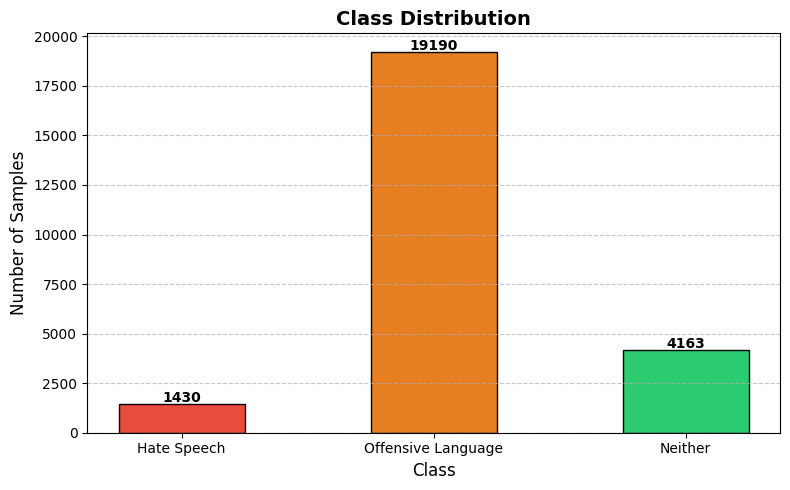

Plot saved to: C:\Users\snsadmin\Desktop\Hate_Speech_Detection\results\class_distribution.png


In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

class_labels = {0: "Hate Speech", 1: "Offensive Language", 2: "Neither"}
class_counts = df["class"].value_counts().sort_index()
colors = ["#e74c3c", "#e67e22", "#2ecc71"]

ax.bar(
    [class_labels[c] for c in class_counts.index],
    class_counts.values,
    color=colors,
    edgecolor="black",
    width=0.5
)

for i, v in enumerate(class_counts.values):
    ax.text(i, v + 100, str(v), ha="center", fontweight="bold")

ax.set_title("Class Distribution", fontsize=14, fontweight="bold")
ax.set_xlabel("Class", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.7)

# Save BEFORE plt.show() to ensure the file is written
RESULTS_PATH = os.path.join(PROJECT_ROOT, "results", "class_distribution.png")
plt.savefig(RESULTS_PATH, bbox_inches="tight", dpi=150)

plt.tight_layout()
plt.show()
print(f"Plot saved to: {RESULTS_PATH}")

**Observation:**  
The dataset is **imbalanced**:
- Class 1 (Offensive Language) dominates with ~77% of records.
- Class 0 (Hate Speech) is the minority with ~6%.
- Class 2 (Neither) has ~17%.

We will proceed without artificial balancing since this reflects real-world distribution.  
Using `stratify=y` during train-test split ensures proportional representation.

---
## 6. Feature and Target Selection

- **Input (X):** `tweet` - the raw text to be classified.
- **Target (y):** `class` - the label (0, 1, or 2).

We do NOT use columns like `count`, `hate_speech`, `offensive_language`, or `neither` as features.  
The model should learn purely from the text content.

In [16]:
X = df["tweet"]
y = df["class"]

print("Input feature (tweet):")
print(X.head())

print("\nTarget (class):")
print(y.head())

Input feature (tweet):
0    !!! RT @mayasolovely: As a woman you shouldn't...
1    !!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2    !!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3    !!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4    !!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...
Name: tweet, dtype: str

Target (class):
0    2
1    1
2    1
3    1
4    1
Name: class, dtype: int64


---
## 7. Text Preprocessing

Raw tweets contain URLs, mentions, punctuation, and extra whitespace that add noise without providing useful classification signals.  
We apply a simple cleaning function to normalize the text.

In [17]:
def clean_text(text):
    """Clean and normalize raw tweet text."""
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove user mentions (e.g. @username)
    text = re.sub(r"@\w+", "", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Collapse extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


X_clean = X.apply(clean_text)
print("Text preprocessing completed.")
print(f"Total tweets cleaned: {len(X_clean)}")

Text preprocessing completed.
Total tweets cleaned: 24783


In [18]:
# Compare original vs cleaned text
comparison = pd.DataFrame({
    "Original": X.head(10).values,
    "Cleaned":  X_clean.head(10).values
})

pd.set_option("display.max_colwidth", 80)
comparison

,Original,Cleaned
0,!!! RT @mayasolovely: As a woman you shouldn't complain about cleaning up yo...,rt as a woman you shouldnt complain about cleaning up your house amp as a ma...
1,!!!!! RT @mleew17: boy dats cold...tyga dwn bad for cuffin dat hoe in the 1s...,rt boy dats coldtyga dwn bad for cuffin dat hoe in the 1st place
2,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby4life: You ever fuck a bitch a...,rt dawg rt you ever fuck a bitch and she start to cry you be confused as shit
3,!!!!!!!!! RT @C_G_Anderson: @viva_based she look like a tranny,rt she look like a tranny
4,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you hear about me might be true o...,rt the shit you hear about me might be true or it might be faker than the bi...
5,"!!!!!!!!!!!!!!!!!!""@T_Madison_x: The shit just blows me..claim you so faithf...",the shit just blows meclaim you so faithful and down for somebody but still ...
6,"!!!!!!""@__BrighterDays: I can not just sit up and HATE on another bitch .. I...",i can not just sit up and hate on another bitch i got too much shit going on
7,!!!!&#8220;@selfiequeenbri: cause I'm tired of you big bitches coming for us...,8220 cause im tired of you big bitches coming for us skinny girls8221
8,""" &amp; you might not get ya bitch back &amp; thats that """,amp you might not get ya bitch back amp thats that
9,""" @rhythmixx_ :hobbies include: fighting Mariam""\n\nbitch",hobbies include fighting mariam bitch


---
## 8. Train-Test Split

We split the dataset into:
- **80% training** - used to fit the model
- **20% testing** - used to evaluate performance on unseen data

`random_state=42` ensures reproducibility.  
`stratify=y` preserves the class proportion in both splits.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")

Training samples : 19826
Testing samples  : 4957


In [20]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
class
1    15352
2     3330
0     1144
Name: count, dtype: int64

Testing class distribution:
class
1    3838
2     833
0     286
Name: count, dtype: int64


---
## 9. TF-IDF Vectorization

**TF-IDF (Term Frequency-Inverse Document Frequency)** converts text into numerical vectors.
- **TF** - how often a word appears in a document.
- **IDF** - how rare the word is across all documents (reduces weight of common words).

**Important:** TF-IDF is fitted ONLY on training data to prevent data leakage.  
The test set is only transformed (not fitted).

In [21]:
tfidf = TfidfVectorizer(
    max_features=10000,   # Keep top 10,000 terms
    ngram_range=(1, 2),   # Use unigrams and bigrams
    min_df=2,             # Ignore terms in fewer than 2 documents
    sublinear_tf=True     # Apply log normalization to term frequency
)

# Fit on training data ONLY - prevents data leakage
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"Training TF-IDF shape : {X_train_tfidf.shape}")
print(f"Testing TF-IDF shape  : {X_test_tfidf.shape}")
print(f"  - rows    = number of samples")
print(f"  - columns = number of TF-IDF features (vocabulary terms)")

Training TF-IDF shape : (19826, 10000)
Testing TF-IDF shape  : (4957, 10000)
  - rows    = number of samples
  - columns = number of TF-IDF features (vocabulary terms)


---
## 10. Train Support Vector Machine

### Why LinearSVC?

TF-IDF produces a **high-dimensional sparse matrix** (thousands of columns, mostly zeros).  
**LinearSVC** is well-suited for this because:
- It works efficiently with high-dimensional sparse data.
- It is fast and scales well to large datasets.
- It generalizes well on text classification tasks.

`C=1.0` is the regularization parameter - higher values = less regularization.

In [22]:
svm_model = LinearSVC(
    C=1.0,
    random_state=42,
    max_iter=2000
)

svm_model.fit(X_train_tfidf, y_train)

print("SVM model training completed successfully.")

SVM model training completed successfully.


---
## 11. Predictions

We use the trained SVM model to predict labels on the unseen test set.

In [23]:
y_pred = svm_model.predict(X_test_tfidf)

print("Actual values (first 10):")
print(y_test.head(10).to_numpy())

print("\nPredicted values (first 10):")
print(y_pred[:10])

Actual values (first 10):
[1 2 1 1 1 0 2 1 1 1]

Predicted values (first 10):
[1 2 1 1 1 1 1 1 1 1]


In [24]:
prediction_results = pd.DataFrame({
    "Actual":    y_test.values,
    "Predicted": y_pred
})

prediction_results.head(20)

,Actual,Predicted
0,1,1
1,2,2
2,1,1
3,1,1
4,1,1
5,0,1
6,2,1
7,1,1
8,1,1
9,1,1


---
## 12. Accuracy

Accuracy = (Number of correct predictions) / (Total predictions)

In [25]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy           : {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

Accuracy           : 0.8886
Accuracy Percentage: 88.86%


---
## 13. Precision, Recall and F1-Score

- **Precision** - Of all samples predicted as a class, how many were actually that class?
- **Recall** - Of all actual samples of a class, how many were correctly detected?
- **F1-Score** - Harmonic mean of precision and recall - a balance between the two.

We use **weighted** averaging because the dataset is imbalanced (accounts for class size).

In [26]:
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall    = recall_score(   y_test, y_pred, average="weighted", zero_division=0)
f1        = f1_score(       y_test, y_pred, average="weighted", zero_division=0)

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Precision : 0.8763
Recall    : 0.8886
F1-Score  : 0.8783


In [27]:
print("Detailed Classification Report:")
print()
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Hate Speech", "Offensive Language", "Neither"],
        zero_division=0
    )
)

Detailed Classification Report:

                    precision    recall  f1-score   support

       Hate Speech       0.55      0.23      0.32       286
Offensive Language       0.91      0.95      0.93      3838
           Neither       0.82      0.82      0.82       833

          accuracy                           0.89      4957
         macro avg       0.76      0.67      0.69      4957
      weighted avg       0.88      0.89      0.88      4957



---
## 14. Confusion Matrix

A confusion matrix shows how many samples of each class were correctly and incorrectly predicted.  
- Diagonal cells = correct predictions  
- Off-diagonal cells = misclassifications

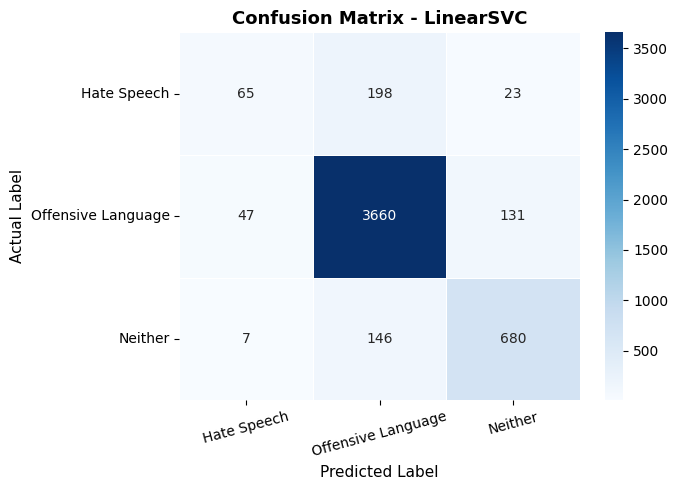

Confusion matrix saved to: C:\Users\snsadmin\Desktop\Hate_Speech_Detection\results\confusion_matrix.png


In [28]:
class_names = ["Hate Speech", "Offensive Language", "Neither"]

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Confusion Matrix - LinearSVC", fontsize=13, fontweight="bold")
ax.set_xlabel("Predicted Label", fontsize=11)
ax.set_ylabel("Actual Label", fontsize=11)
plt.xticks(rotation=15)
plt.yticks(rotation=0)

# Save BEFORE plt.show()
CM_PATH = os.path.join(PROJECT_ROOT, "results", "confusion_matrix.png")
plt.savefig(CM_PATH, bbox_inches="tight", dpi=150)

plt.tight_layout()
plt.show()
print(f"Confusion matrix saved to: {CM_PATH}")

---
## 15. Custom Text Prediction

We can use the trained model and TF-IDF vectorizer to classify any new sentence.

In [29]:
label_mapping = {
    0: "Hate Speech",
    1: "Offensive Language",
    2: "Neither"
}

def predict_text(text):
    """Predict the class of a given text string."""
    cleaned = clean_text(text)
    vec     = tfidf.transform([cleaned])
    pred    = svm_model.predict(vec)[0]
    return label_mapping.get(pred, str(pred))


# Test with neutral example sentences
test_sentences = [
    "I really enjoyed this movie.",
    "The weather is nice today.",
    "This product is not good at all."
]

print("Custom Predictions:")
print("-" * 55)
for sentence in test_sentences:
    print(f"Text       : {sentence}")
    print(f"Prediction : {predict_text(sentence)}")
    print("-" * 55)

Custom Predictions:
-------------------------------------------------------
Text       : I really enjoyed this movie.
Prediction : Neither
-------------------------------------------------------
Text       : The weather is nice today.
Prediction : Neither
-------------------------------------------------------
Text       : This product is not good at all.
Prediction : Neither
-------------------------------------------------------


In [30]:
# To classify your own text, call predict_text() with any string.
# Uncomment the lines below and replace the custom_text value:
#
#   custom_text = input("Enter a sentence for classification: ")
#   print("Prediction:", predict_text(custom_text))

# Fixed demonstration example:
custom_text = "This is a great day for everyone!"
print(f"Text       : {custom_text}")
print(f"Prediction : {predict_text(custom_text)}")

Text       : This is a great day for everyone!
Prediction : Neither


---
## 16. Save Model and Vectorizer

We save both the trained SVM model and TF-IDF vectorizer using `pickle`.  
Both must be saved together - the vectorizer is required to transform any new text  
in the same way as the training data before the model can make predictions.

In [31]:
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
os.makedirs(MODELS_DIR, exist_ok=True)

SVM_MODEL_PATH = os.path.join(MODELS_DIR, "svm_model.pkl")
TFIDF_PATH     = os.path.join(MODELS_DIR, "tfidf_vectorizer.pkl")

with open(SVM_MODEL_PATH, "wb") as f:
    pickle.dump(svm_model, f)

with open(TFIDF_PATH, "wb") as f:
    pickle.dump(tfidf, f)

print(f"SVM model saved        : {os.path.exists(SVM_MODEL_PATH)}")
print(f"TF-IDF vectorizer saved: {os.path.exists(TFIDF_PATH)}")

SVM model saved        : True
TF-IDF vectorizer saved: True


---
## Final Model Evaluation Summary

In [32]:
evaluation_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score":  [accuracy,   precision,   recall,   f1]
})

evaluation_results["Score"] = evaluation_results["Score"].map("{:.4f}".format)
evaluation_results

,Metric,Score
0,Accuracy,0.8886
1,Precision,0.8763
2,Recall,0.8886
3,F1-Score,0.8783


---
# Conclusion

This project demonstrated a complete ML pipeline for Hate Speech Detection:

1. **Dataset Loaded** - `labeled_data.csv` with 24,783 labeled tweets.
2. **Text Cleaned** - URLs, mentions, punctuation, and extra whitespace removed.
3. **TF-IDF Applied** - Text converted into numerical feature vectors.
4. **Train-Test Split** - 80% for training, 20% for testing (stratified).
5. **LinearSVC Trained** - Support Vector Machine fitted on TF-IDF features.
6. **Predictions Generated** - Model evaluated on unseen test data.
7. **Metrics Calculated** - Accuracy, Precision, Recall, F1-Score.
8. **Confusion Matrix Plotted** - Visualizes classification performance per class.
9. **Model Saved** - Both `svm_model.pkl` and `tfidf_vectorizer.pkl` persisted for future use.

The model can classify any new tweet into: **Hate Speech**, **Offensive Language**, or **Neither**.